# Práctica de laboratorio: Buscador visual CBIR (HSV + GLCM)

**Objetivo:** implementar y evaluar un sistema CBIR tradicional (sin CNN) con histogramas HSV, propiedades de la GLCM (contraste y homogeneidad), distancia euclidiana y fusión ponderada. Se compara el efecto del color, la textura y su combinación en el ranking Top-5 con **Precision@5**.

**Criterio de selección de las 100 imágenes**, semilla = 42:
- 5 categorías: `beach`, `bus`, `dinosaurs`, `flowers` y `mountains`. Beach y Mountains comparten colores (cielo azul, tonos tierra), lo que pone a prueba al descriptor de color. Bus y Flowers se distinguen sobre todo por el color. Dinosaurs tiene fondo uniforme.
- 20 imágenes por clase elegidas con `random.Random(42).sample` sobre los números 1–100 de cada categoría.
- Las clases verdaderas están en `etiquetas.csv` (`archivo, categoria, origen`).

In [1]:
# %pip install -r requirements.txt
# python descargar_dataset.py   (descarga las 100 imágenes y crea etiquetas.csv)
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from skimage.feature import graycomatrix, graycoprops

SEMILLA = 42                     # semilla que descargar_dataset.py
np.random.seed(SEMILLA)

DATA = Path('imagenes')
df = pd.read_csv('etiquetas.csv')
files  = [DATA / a for a in df.archivo]
labels = df.categoria.tolist()
N = len(files)

# Colores fijos para las gráficas
AZUL, NARANJA, AQUA, GRIS = '#2a78d6', '#eb6834', '#1baf7a', '#52514e'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'figure.dpi': 90})
print('Imágenes:', N, '| Clases:', sorted(set(labels)))

Imágenes: 100 | Clases: ['beach', 'bus', 'dinosaurs', 'flowers', 'mountains']


## 1. Preparación y exploración
### 1.1 Validar formatos y categorías
Se comprueba que cada archivo del CSV exista, sea `.jpg`, se pueda leer como imagen a color y que haya 20 imágenes por clase.

In [2]:
assert N == 100 and df.archivo.is_unique, 'Se esperaban 100 archivos distintos'
tamanos = {}
for p in files:
    assert p.suffix.lower() == '.jpg' and p.exists(), f'Falta o formato inválido: {p}'
    img = cv2.imread(str(p))                     # OpenCV lee en orden BGR
    assert img is not None and img.ndim == 3 and img.shape[2] == 3, f'No es una imagen a color: {p}'
    tamanos[img.shape[:2]] = tamanos.get(img.shape[:2], 0) + 1

conteo = df.categoria.value_counts().sort_index()
assert (conteo == 20).all(), 'Cada categoría debe tener 20 imágenes'
print(conteo.to_string())
print('\nTamaños originales (alto, ancho):', tamanos)

categoria
beach        20
bus          20
dinosaurs    20
flowers      20
mountains    20

Tamaños originales (alto, ancho): {(384, 256): 16, (256, 384): 84}


### 1.2 Cuadrícula de 12 fotografías

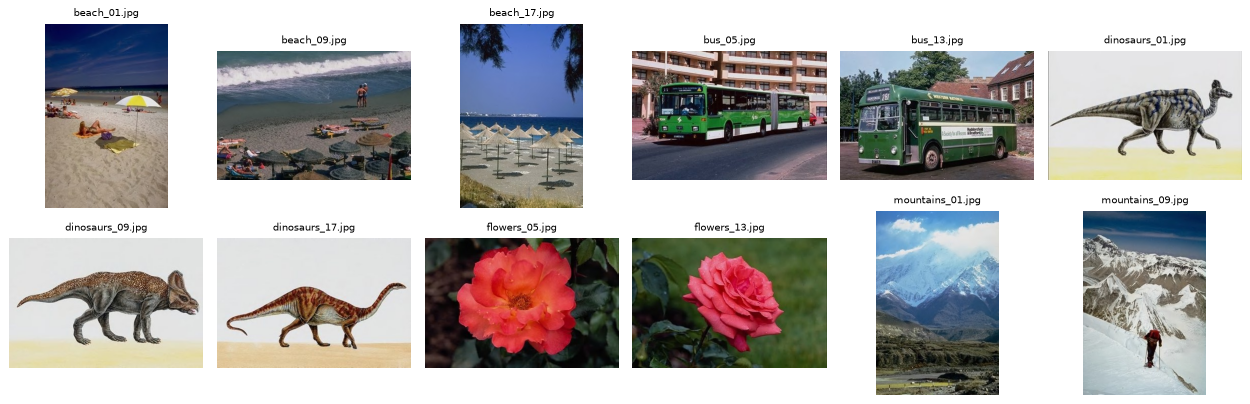

In [3]:
def rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # matplotlib espera RGB

fig, axes = plt.subplots(2, 6, figsize=(14, 4.6))
for ax, p in zip(axes.flat, files[::8][:12]):   # una de cada 8 -> cubre las 5 clases
    ax.imshow(rgb(cv2.imread(str(p)))); ax.set_title(p.name, fontsize=8); ax.axis('off')
plt.tight_layout(); plt.show()

### 1.3 Redimensionar sin deformar (relleno hasta 128 × 128)
1. Se escala el **lado mayor** a 128 con el mismo factor para el alto y el ancho, así se conserva la proporción. Una foto de 384×256 queda en 128×85.
2. Se rellena con negro hasta 128×128.
3. Se guarda una **máscara** (255 = píxel real, 0 = relleno). El relleno no es parte de la foto, así que no debe entrar en los descriptores. El histograma se calcula con la máscara y la GLCM sobre la imagen sin relleno.

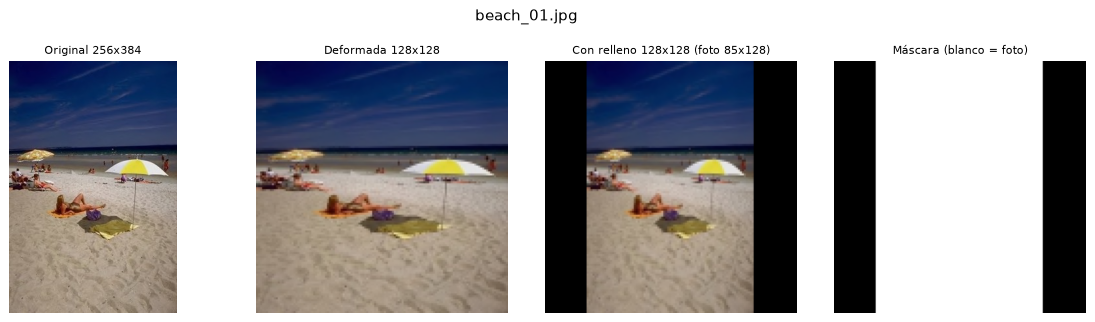

Fracción de relleno en esta imagen: 33.6%


In [4]:
TAM = 128

def redimensionar(img, tam=TAM):
    # Devuelve: imagen con relleno (tam x tam), máscara de píxeles reales e imagen sin relleno
    h, w = img.shape[:2]
    s = tam / max(h, w)                          # mismo factor en ambos ejes
    nh, nw = round(h * s), round(w * s)
    chica = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_AREA)
    arriba, izq = (tam - nh) // 2, (tam - nw) // 2
    con_relleno = cv2.copyMakeBorder(chica, arriba, tam - nh - arriba, izq, tam - nw - izq,
                                     cv2.BORDER_CONSTANT, value=(0, 0, 0))
    mascara = np.zeros((tam, tam), np.uint8)
    mascara[arriba:arriba + nh, izq:izq + nw] = 255
    return con_relleno, mascara, chica

def cargar(i):
    return redimensionar(cv2.imread(str(files[i])))

# Comparación con una foto vertical: deformar vs rellenar
iv = next(i for i, p in enumerate(files) if cv2.imread(str(p)).shape[0] > cv2.imread(str(p)).shape[1])
orig = cv2.imread(str(files[iv]))
deformada = cv2.resize(orig, (TAM, TAM), interpolation=cv2.INTER_AREA)
con_relleno, mascara, chica = redimensionar(orig)

fig, axs = plt.subplots(1, 4, figsize=(13, 3.6))
for ax, im, t in zip(axs, [orig, deformada, con_relleno, mascara],
                     [f'Original {orig.shape[1]}x{orig.shape[0]}', 'Deformada 128x128',
                      f'Con relleno 128x128 (foto {chica.shape[1]}x{chica.shape[0]})', 'Máscara (blanco = foto)']):
    ax.imshow(rgb(im) if im.ndim == 3 else im, cmap='gray'); ax.set_title(t, fontsize=9); ax.axis('off')
plt.suptitle(files[iv].name); plt.tight_layout(); plt.show()
print(f'Fracción de relleno en esta imagen: {1 - mascara.mean() / 255:.1%}')

**¿Por qué no se debe deformar la imagen?** Al forzar 384×256 a 128×128, un eje se comprime 3× y el otro solo 2×. Los objetos cambian de forma (un autobús se ve más alto y angosto) y, sobre todo, la **textura** cambia: la GLCM compara píxeles vecinos a distancia d = 1 en horizontal, y si un eje se comprimió más que el otro, "1 píxel" representa distancias reales distintas en fotos horizontales y verticales. Entonces el contraste y la homogeneidad medirían la deformación y no la textura. Con relleno todas las fotos usan la **misma escala** en ambos ejes.

El relleno negro, en cambio, tiene que excluirse. En una foto de 384×256, un tercio del cuadro de 128×128 es relleno. Si se contara, todas las imágenes tendrían un pico artificial en el bin "negro" del histograma y la GLCM tendría una gran zona plana que inflaría la homogeneidad.

## 2. Descriptores de color: histograma HSV (8 × 4 × 4 = 128)


- **H** (tono, qué color es): 8 bins. En OpenCV, H va de 0 a 179, no de 0 a 255.
- **S** (saturación, qué tan puro es el color): 4 bins de 0 a 255.
- **V** (valor, qué tan claro es): 4 bins de 0 a 255.
- El bin 3D `(h, s, v)` queda en la posición `k = h·16 + s·4 + v` del vector de 128.

Se normaliza porque las fotos tienen distinto número de píxeles reales (128×85 contra 85×128 más el relleno). Así se compara la *proporción* de cada color y no la cantidad.

In [5]:
def hist_hsv(img, mascara=None):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    h = cv2.calcHist([hsv], [0, 1, 2], mascara, [8, 4, 4], [0, 180, 0, 256, 0, 256]).flatten()
    return h / h.sum()                           # normalizar: suma = 1

img, m, _ = cargar(0)
v = hist_hsv(img, m)
print('Dimensión:', v.shape[0], '| suma =', round(v.sum(), 6))
print('Masa en el bin (0,0,0) "negro"  con máscara:', round(v[0], 3),
      '| sin máscara:', round(hist_hsv(img)[0], 3))

Dimensión: 128 | suma = 1.0
Masa en el bin (0,0,0) "negro"  con máscara: 0.0 | sin máscara: 0.336


### Histogramas de dos imágenes de la misma categoría y una de categoría distinta

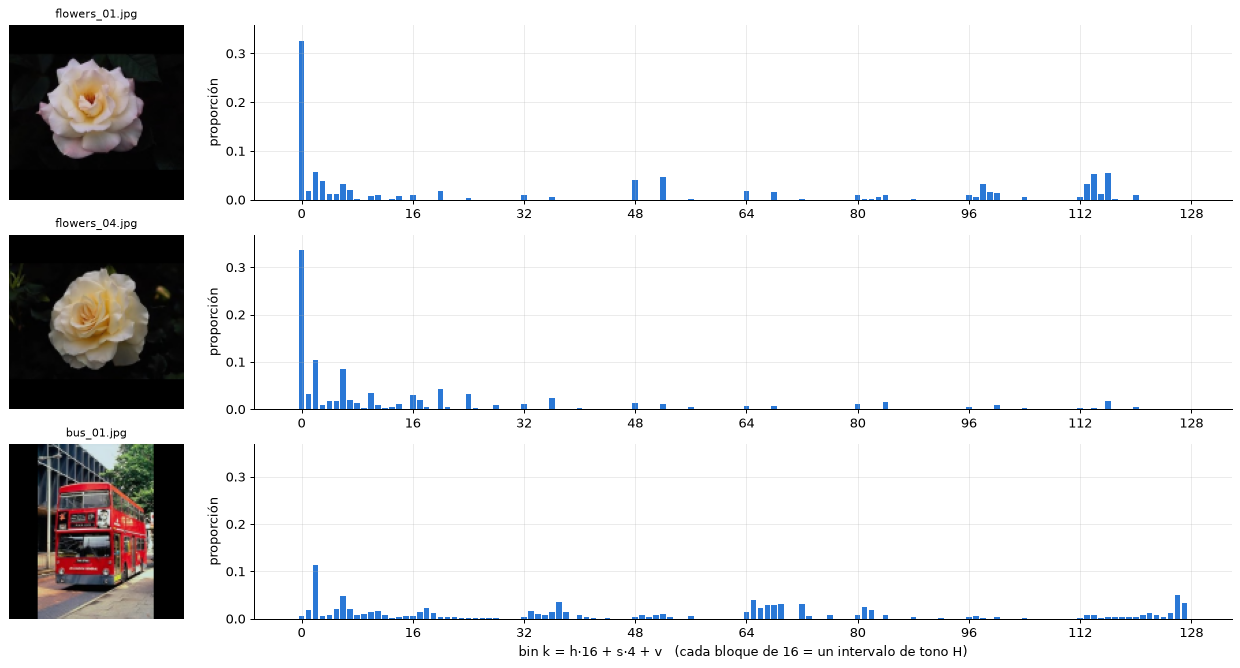

d(flowers_01, flowers_04) = 0.137   (misma categoría)
d(flowers_01, bus_01)     = 0.361   (categoría distinta)


In [6]:
def idx(nombre):
    return df.index[df.archivo == nombre][0]

ejemplos = ['flowers_01.jpg', 'flowers_04.jpg', 'bus_01.jpg']
H = {}
fig, axs = plt.subplots(3, 2, figsize=(14, 7.5), gridspec_kw={'width_ratios': [1, 5]})
for fila, nombre in enumerate(ejemplos):
    img, m, _ = cargar(idx(nombre))
    H[nombre] = hist_hsv(img, m)
    axs[fila, 0].imshow(rgb(img)); axs[fila, 0].set_title(nombre, fontsize=9); axs[fila, 0].axis('off')
    axs[fila, 1].bar(np.arange(128), H[nombre], width=0.8, color=AZUL)
    axs[fila, 1].set_ylim(0, max(h.max() for h in H.values()) * 1.1)
    axs[fila, 1].set_xticks(np.arange(0, 129, 16))
    axs[fila, 1].set_ylabel('proporción')
axs[-1, 1].set_xlabel('bin k = h·16 + s·4 + v   (cada bloque de 16 = un intervalo de tono H)')
plt.tight_layout(); plt.show()

d = lambda a, b: np.linalg.norm(H[a] - H[b])
print(f"d(flowers_01, flowers_04) = {d('flowers_01.jpg', 'flowers_04.jpg'):.3f}   (misma categoría)")
print(f"d(flowers_01, bus_01)     = {d('flowers_01.jpg', 'bus_01.jpg'):.3f}   (categoría distinta)")

Las dos flores tienen alrededor de un tercio de sus píxeles en el **bin 0** (S y V bajos = casi negro). Ese pico no viene del relleno, que ya está excluido con la máscara: es el **fondo oscuro** típico de las fotos de flores de esta colección. Además comparten los bins de tonos cálidos claros de los pétalos (bloques 0–16). Por eso su distancia (0.137) es menor que la distancia con el autobús (0.361), que reparte su masa entre el rojo, el verde de los árboles y el gris de la calle.

Como en la práctica anterior, el histograma dice **cuánto** hay de cada color, pero **no dónde** está ni **qué objeto** lo tiene. El parecido entre las flores se debe en parte al fondo y no solo a la flor.

## 3. Descriptores de textura: GLCM


- **GLCM(i, j)**: cuántas veces un píxel de nivel *i* tiene a su derecha (d = 1, θ = 0°) un píxel de nivel *j*. Con `symmetric=True` también se cuenta el par al revés (j, i).
- **P(i, j)**: la GLCM dividida entre su suma, es decir, la probabilidad del par.
- **Contraste C**: pesa cada par por (i − j)². Es alto si los vecinos tienen niveles muy distintos (bordes, textura rugosa).
- **Homogeneidad H**: pesa cada par por 1/(1 + (i − j)²). Es alta si los vecinos son parecidos (zonas lisas). Vale 1 si toda la masa está en la diagonal.

### Ejemplo(4 niveles, imagen de 4×4)
```
imagen         pares horizontales (d=1)       GLCM simétrica (cuentas)
0 0 1 1        (0,0) (0,1) (1,1)                   j=0 j=1 j=2 j=3
0 0 1 1        (0,0) (0,1) (1,1)              i=0   4   2   1   0
0 2 2 2        (0,2) (2,2) (2,2)              i=1   2   4   0   0
2 2 3 3        (2,2) (2,3) (3,3)              i=2   1   0   6   1
                                              i=3   0   0   1   2      suma = 24
```
```
C = [ (0-1)²·(2+2) + (0-2)²·(1+1) + (2-3)²·(1+1) ] / 24 = (4 + 8 + 2) / 24 = 14/24 = 0.583
H = [ (4+4+6+2)/1 + (2+2)/2 + (1+1)/5 + (1+1)/2 ] / 24 = (16 + 2 + 0.4 + 1) / 24 = 19.4/24 = 0.808
```

In [ ]:
ejemplo = np.array([[0, 0, 1, 1],
                    [0, 0, 1, 1],
                    [0, 2, 2, 2],
                    [2, 2, 3, 3]], dtype=np.uint8)
G = graycomatrix(ejemplo, distances=[1], angles=[0], levels=4, symmetric=True, normed=False)
print('GLCM (cuentas):\n', G[:, :, 0, 0])
Gn = graycomatrix(ejemplo, distances=[1], angles=[0], levels=4, symmetric=True, normed=True)
print('Contraste    =', round(graycoprops(Gn, 'contrast')[0, 0], 3), '  (a mano: 0.583)')
print('Homogeneidad =', round(graycoprops(Gn, 'homogeneity')[0, 0], 3), '  (a mano: 0.808)')

GLCM (cuentas):
 [[4 2 1 0]
 [2 4 0 0]
 [1 0 6 1]
 [0 0 1 2]]
Contraste    = 0.583   (a mano: 0.583)
Homogeneidad = 0.808   (a mano: 0.808)


### 3.1 GLCM de las fotografías
Para cada foto: se convierte a grises, se cuantiza a 8 niveles (gris // 32, porque 256 / 8 = 32 tonos por nivel) y se construye la GLCM sobre la imagen **sin relleno**.

In [ ]:
def gris8(img):
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return (g // 32).astype(np.uint8)            # 0..255 -> 0..7

def glcm(img):
    return graycomatrix(gris8(img), distances=[1], angles=[0], levels=8, symmetric=True, normed=True)

def desc_textura(img):
    G = glcm(img)
    return np.array([graycoprops(G, 'contrast')[0, 0], graycoprops(G, 'homogeneity')[0, 0]])

# Verificación con una foto real: suma = 1, simetría y fórmulas a mano vs graycoprops
_, _, foto = cargar(0)
P = glcm(foto)[:, :, 0, 0]
i, j = np.indices(P.shape)
print(files[0].name)
print('Suma de P(i,j) =', round(P.sum(), 6), '| simétrica:', np.allclose(P, P.T))
print('Contraste    a mano:', round(np.sum((i - j) ** 2 * P), 4), '| graycoprops:', round(desc_textura(foto)[0], 4))
print('Homogeneidad a mano:', round(np.sum(P / (1 + (i - j) ** 2)), 4), '| graycoprops:', round(desc_textura(foto)[1], 4))

beach_01.jpg
Suma de P(i,j) = 1.0 | simétrica: True
Contraste    a mano: 0.1926 | graycoprops: 0.1926
Homogeneidad a mano: 0.9228 | graycoprops: 0.9228


### 3.2 Indexar la colección
Se calculan los descriptores de las 100 imágenes una sola vez. Los vectores quedan así:
- COLOR: 100 × 128, el histograma HSV.
- TEXTURA: 100 × 2, contraste y homogeneidad.

In [ ]:
COLOR, T_CRUDO = [], []
for k in range(N):
    img, m, foto = cargar(k)
    COLOR.append(hist_hsv(img, m))
    T_CRUDO.append(desc_textura(foto))
COLOR, T_CRUDO = np.array(COLOR), np.array(T_CRUDO)

tabla_tex = pd.DataFrame(T_CRUDO, columns=['contraste', 'homogeneidad'])
tabla_tex['categoria'] = labels
print('COLOR:', COLOR.shape, '| TEXTURA:', T_CRUDO.shape)
print(tabla_tex.groupby('categoria').mean().round(3))
print('\nRango en la colección:\n', tabla_tex[['contraste', 'homogeneidad']].agg(['min', 'max', 'std']).round(3))

COLOR: (100, 128) | TEXTURA: (100, 2)
           contraste  homogeneidad
categoria                         
beach          0.351         0.881
bus            0.743         0.831
dinosaurs      0.377         0.915
flowers        0.213         0.925
mountains      0.415         0.867

Rango en la colección:
      contraste  homogeneidad
min      0.108         0.765
max      1.154         0.955
std      0.222         0.045


Las dos propiedades tienen escalas muy distintas. El contraste va de 0.11 a 1.15 (desviación 0.22), mientras que la homogeneidad apenas se mueve entre 0.77 y 0.96 (desviación 0.045). Con la distancia euclidiana sobre los valores crudos, el contraste dominaría y la homogeneidad casi no influiría.

Por eso cada propiedad se **estandariza con la media y la desviación estándar de toda la colección**: z = (x − media) / desviación. Son parámetros fijos, calculados una vez sobre las 100 imágenes y no por consulta.

In [ ]:
TEX_MEDIA, TEX_STD = T_CRUDO.mean(axis=0), T_CRUDO.std(axis=0)   # parámetros fijos de la colección
TEXTURA = (T_CRUDO - TEX_MEDIA) / TEX_STD
print('media =', TEX_MEDIA.round(4), '| desviación =', TEX_STD.round(4))

media = [0.4199 0.8838] | desviación = [0.2207 0.0452]


### 3.3 Una matriz GLCM real: la foto más lisa contra la más rugosa

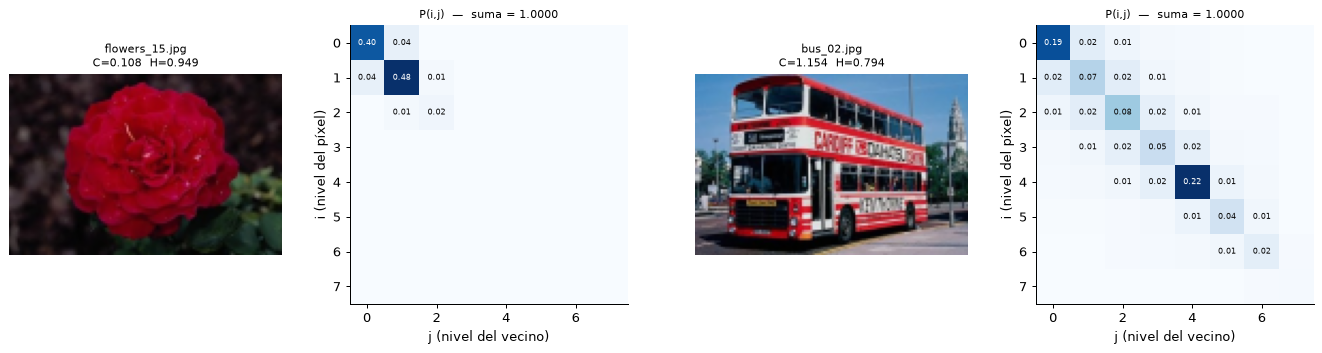

In [ ]:
lisa, rugosa = int(np.argmin(T_CRUDO[:, 0])), int(np.argmax(T_CRUDO[:, 0]))
fig, axs = plt.subplots(1, 4, figsize=(15, 3.8), gridspec_kw={'width_ratios': [1, 1.15, 1, 1.15]})
for col, k in zip([0, 2], [lisa, rugosa]):
    _, _, foto = cargar(k)
    P = glcm(foto)[:, :, 0, 0]
    axs[col].imshow(rgb(foto)); axs[col].axis('off')
    axs[col].set_title(f'{files[k].name}\nC={T_CRUDO[k,0]:.3f}  H={T_CRUDO[k,1]:.3f}', fontsize=9)
    im = axs[col + 1].imshow(P, cmap='Blues', vmin=0)
    for (a, b), val in np.ndenumerate(P):
        if val >= 0.005:
            axs[col + 1].text(b, a, f'{val:.2f}', ha='center', va='center', fontsize=6.5,
                              color='white' if val > P.max() * 0.6 else '#0b0b0b')
    axs[col + 1].set_title(f'P(i,j)  —  suma = {P.sum():.4f}', fontsize=9)
    axs[col + 1].set_xlabel('j (nivel del vecino)'); axs[col + 1].set_ylabel('i (nivel del píxel)')
    axs[col + 1].grid(False)
plt.tight_layout(); plt.show()

En ambas matrices casi toda la probabilidad está **sobre la diagonal** (i = j): en fotos naturales, la mayoría de los vecinos horizontales caen en el mismo nivel de gris. La foto lisa concentra la masa en pocas celdas de la diagonal. La rugosa la reparte en las celdas vecinas a la diagonal (|i − j| = 1, 2), y eso es justo lo que suma al contraste y resta a la homogeneidad.

La foto más "lisa" de la colección es una rosa roja **oscura**. Al cuantizar a 8 niveles, casi todos sus píxeles caen en los niveles 0 y 1, así que la textura de los pétalos desaparece. Esto se retoma en la pregunta de reflexión 2.

## 4. Recuperación Top-5
Dada una consulta *q*, se calcula la distancia euclidiana a todas las imágenes del índice, se ordena de menor a mayor y se **excluye la propia consulta**.

Una imagen es relevante si pertenece a la misma categoría que la consulta:



In [12]:
def distancias(q, X):
    return np.linalg.norm(X - X[q], axis=1)       # distancia euclidiana a todo el índice

def ranking(d, q, k=5):
    d = d.copy(); d[q] = np.inf                   # excluir la propia consulta
    orden = np.argsort(d)[:k]                     # de menor a mayor distancia
    return [(int(i), float(d[i])) for i in orden]

def precision_at_k(q, resultados):
    return sum(labels[i] == labels[q] for i, _ in resultados) / len(resultados)

def mostrar(q, resultados, titulo=''):
    fig, axs = plt.subplots(1, len(resultados) + 1, figsize=(15, 3.6))
    axs[0].imshow(rgb(cargar(q)[0])); axs[0].set_title(f'CONSULTA\n{files[q].name}', fontsize=9, fontweight='bold')
    for ax, (i, d) in zip(axs[1:], resultados):
        ok = labels[i] == labels[q]
        ax.imshow(rgb(cargar(i)[0]))
        ax.set_title(f"{'✓' if ok else '✗'} {files[i].name}\nd = {d:.3f}", fontsize=9,
                     color='#0b0b0b' if ok else '#d03b3b')
    for ax in axs: ax.axis('off')
    plt.suptitle(f'{titulo}   P@5 = {precision_at_k(q, resultados):.2f}', fontsize=11, fontweight='bold')
    plt.tight_layout(rect=(0, 0, 1, 0.9)); plt.show()

def buscar(q, descriptor='color', k=5):
    X = COLOR if descriptor == 'color' else TEXTURA
    return ranking(distancias(q, X), q, k)

### Consultas seleccionadas
Se usan **tres consultas de categorías distintas**. Se eligieron después de explorar los resultados para que cada una ilustre uno de los casos que pide la actividad 6: una donde gana el color, una donde gana la textura y una donde la fusión mejora a ambos. Como esa elección favorece casos "interesantes", en la sección 5 también se reporta el promedio usando **las 100 imágenes como consulta**.

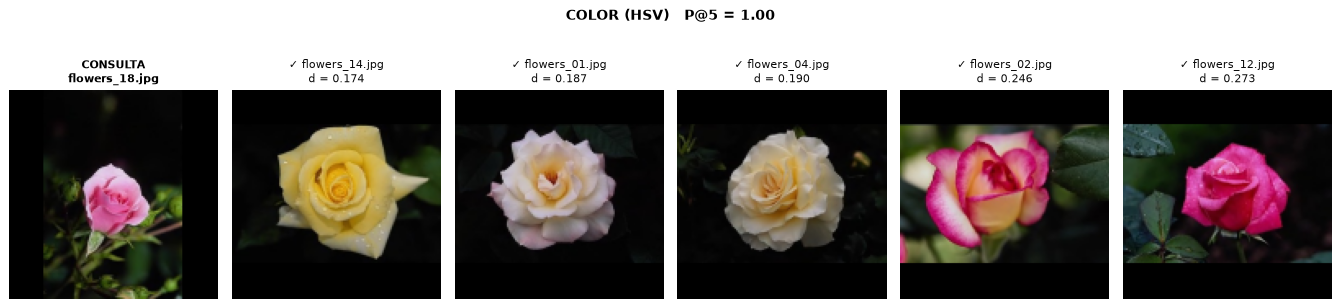

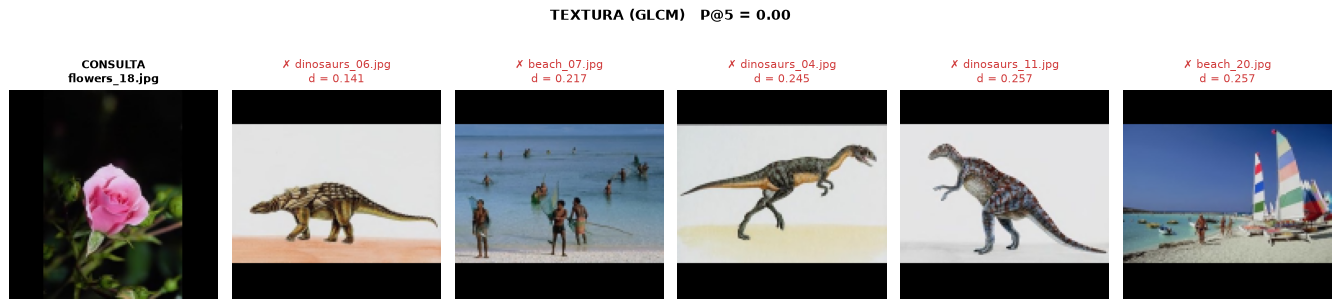

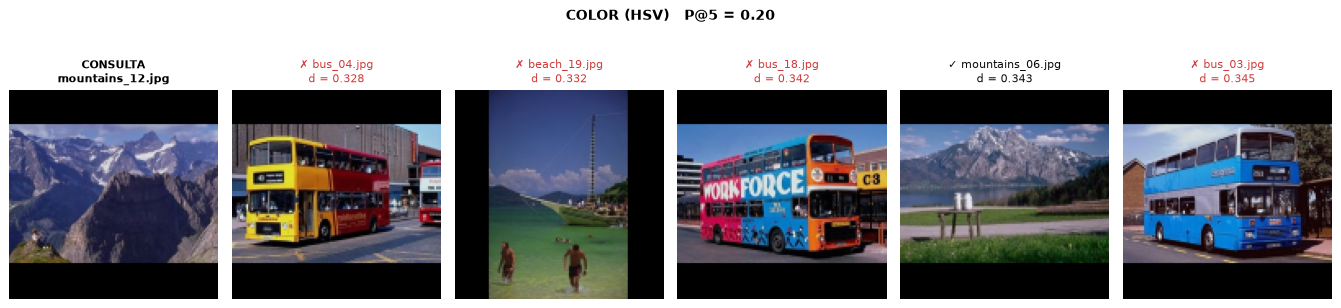

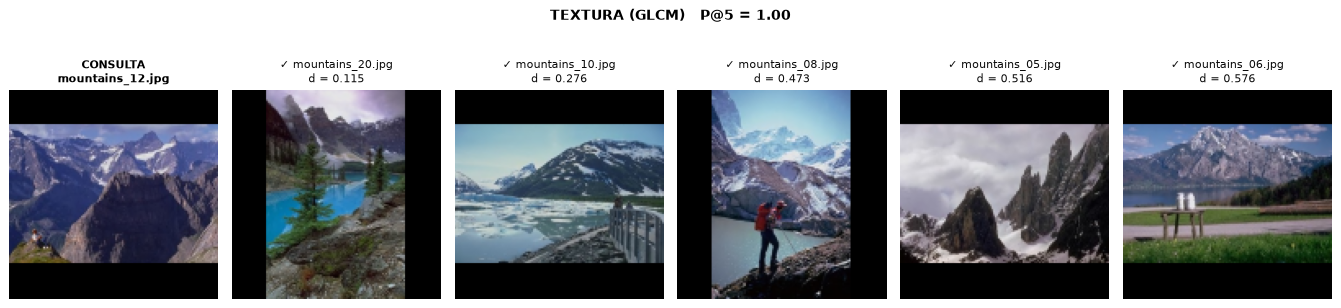

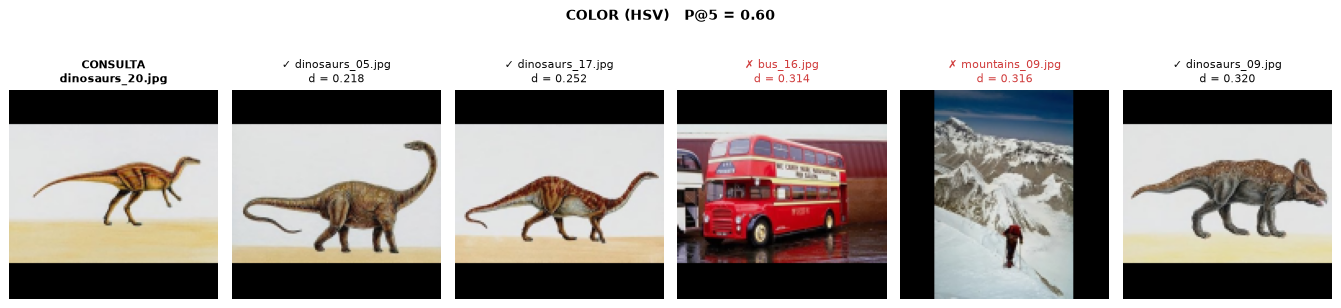

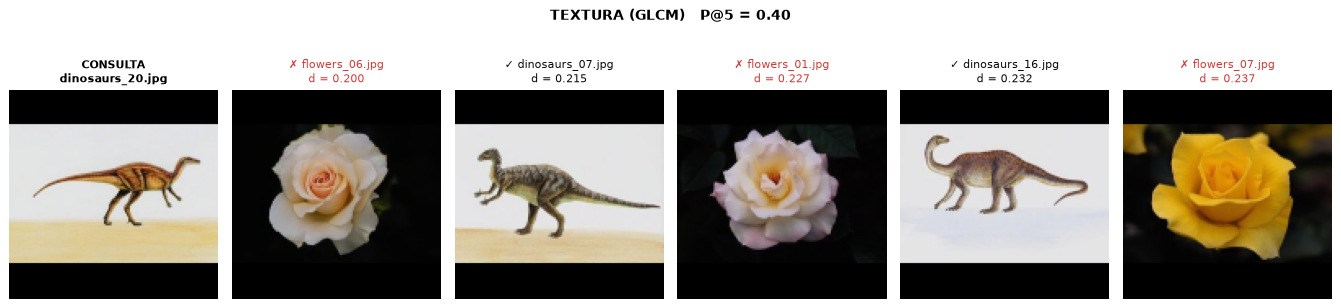

In [13]:
CONSULTAS = ['flowers_18.jpg', 'mountains_12.jpg', 'dinosaurs_20.jpg']
Q = [idx(n) for n in CONSULTAS]

for q in Q:
    mostrar(q, buscar(q, 'color'),   'COLOR (HSV)')
    mostrar(q, buscar(q, 'textura'), 'TEXTURA (GLCM)')

## 5. Fusión y evaluación

Antes de sumar, cada distancia se **divide entre la distancia máxima entre dos imágenes cualesquiera de la colección**. Es la misma idea que "normalizar por la máxima" del formulario y deja ambas distancias entre 0 y 1. La regla es fija: el máximo se calcula una vez sobre las 100 × 100 parejas, no por consulta.

- α = 1 → solo color; α = 0 → solo textura.
- Dividir entre una constante no cambia el orden, así que α = 1 y α = 0 dan los mismos Top-5 que la sección 4.

In [14]:
D_COLOR = np.linalg.norm(COLOR[:, None] - COLOR[None], axis=2)       # 100 x 100
D_TEXT  = np.linalg.norm(TEXTURA[:, None] - TEXTURA[None], axis=2)
fuera_diag = ~np.eye(N, dtype=bool)                                  # sin comparar una imagen consigo misma
MAX_COLOR, MAX_TEXT = D_COLOR[fuera_diag].max(), D_TEXT[fuera_diag].max()

print(f'Color:   máx = {MAX_COLOR:.3f}  media = {D_COLOR[fuera_diag].mean():.3f}  ->  media normalizada = {D_COLOR[fuera_diag].mean()/MAX_COLOR:.3f}')
print(f'Textura: máx = {MAX_TEXT:.3f}  media = {D_TEXT[fuera_diag].mean():.3f}  ->  media normalizada = {D_TEXT[fuera_diag].mean()/MAX_TEXT:.3f}')

def buscar_fusion(q, alfa, k=5):
    D = alfa * D_COLOR[q] / MAX_COLOR + (1 - alfa) * D_TEXT[q] / MAX_TEXT
    return ranking(D, q, k)

ALFAS = [0, 0.25, 0.50, 0.75, 1.0]

Color:   máx = 0.823  media = 0.448  ->  media normalizada = 0.544
Textura: máx = 5.995  media = 1.651  ->  media normalizada = 0.275


### 5.1 Precision@5 para las tres consultas y los cinco pesos

In [15]:
tabla = pd.DataFrame({f'α={a}': [precision_at_k(q, buscar_fusion(q, a)) for q in Q] for a in ALFAS},
                     index=[f'Consulta {n+1} ({CONSULTAS[n]})' for n in range(3)])
tabla.loc['Promedio'] = tabla.mean()
tabla.round(3)

,α=0,α=0.25,α=0.5,α=0.75,α=1.0
Consulta 1 (flowers_18.jpg),0.000,1.0,1.000,1.000,1.0
Consulta 2 (mountains_12.jpg),1.000,0.8,0.600,0.600,0.2
Consulta 3 (dinosaurs_20.jpg),0.400,0.6,1.000,1.000,0.6
Promedio,0.467,0.8,0.867,0.867,0.6


### 5.2 Tabla de resultados

In [16]:
def mejor(fila):
    m = fila.max()
    alfas = [c.replace('α=', '') for c in fila.index if np.isclose(fila[c], m)]
    return f"{', '.join(alfas)} / {m:.2f}"

resumen = pd.DataFrame({
    'Color P@5':    tabla['α=1.0'],
    'Textura P@5':  tabla['α=0'],
    'Mejor α / P@5': tabla.apply(mejor, axis=1),
})
resumen.index = ['Consulta 1', 'Consulta 2', 'Consulta 3', 'Promedio']
resumen.round(3)

,Color P@5,Textura P@5,Mejor α / P@5
Consulta 1,1.0,0.000,"0.25, 0.5, 0.75, 1.0 / 1.00"
Consulta 2,0.2,1.000,0 / 1.00
Consulta 3,0.6,0.400,"0.5, 0.75 / 1.00"
Promedio,0.6,0.467,"0.5, 0.75 / 0.87"


### 5.3 Promedio con las 100 imágenes como consulta
Para comprobar que las conclusiones no dependen solo de las tres consultas elegidas.

In [17]:
p5_todas = pd.DataFrame({f'α={a}': [precision_at_k(q, buscar_fusion(q, a)) for q in range(N)] for a in ALFAS})
p5_todas['categoria'] = labels
por_clase = p5_todas.groupby('categoria').mean()
por_clase.loc['PROMEDIO (100)'] = p5_todas.drop(columns='categoria').mean()
por_clase.round(3)

,α=0,α=0.25,α=0.5,α=0.75,α=1.0
categoria,,,,,
beach,0.330,0.450,0.380,0.460,0.430
bus,0.690,0.880,0.940,0.940,0.880
dinosaurs,0.820,0.980,0.980,0.980,0.940
flowers,0.570,0.870,0.950,0.970,0.690
mountains,0.320,0.290,0.270,0.390,0.400
PROMEDIO (100),0.546,0.694,0.704,0.748,0.668


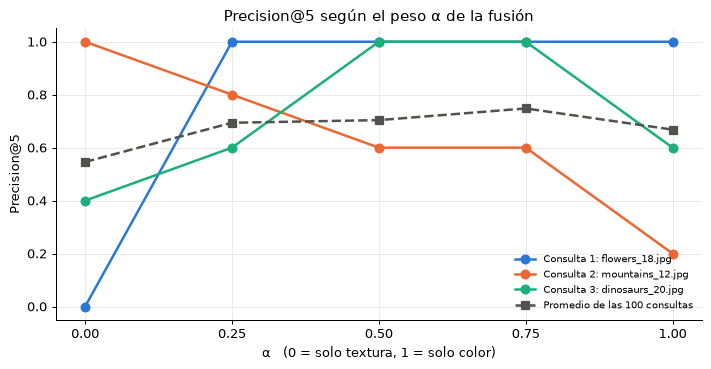

In [18]:
fig, ax = plt.subplots(figsize=(8, 4.2))
for n, (q, color) in enumerate(zip(Q, [AZUL, NARANJA, AQUA])):
    y = tabla.iloc[n].values
    ax.plot(ALFAS, y, marker='o', markersize=7, linewidth=2, color=color, label=f'Consulta {n+1}: {CONSULTAS[n]}')
ax.plot(ALFAS, por_clase.loc['PROMEDIO (100)'].values, marker='s', markersize=7, linewidth=2,
        linestyle='--', color=GRIS, label='Promedio de las 100 consultas')
ax.set_xticks(ALFAS); ax.set_ylim(-0.05, 1.05)
ax.set_xlabel('α   (0 = solo textura, 1 = solo color)'); ax.set_ylabel('Precision@5')
ax.set_title('Precision@5 según el peso α de la fusión')
ax.legend(fontsize=8, loc='lower right', frameon=False)
plt.tight_layout(); plt.show()

### 5.4 Top-5 con fusión

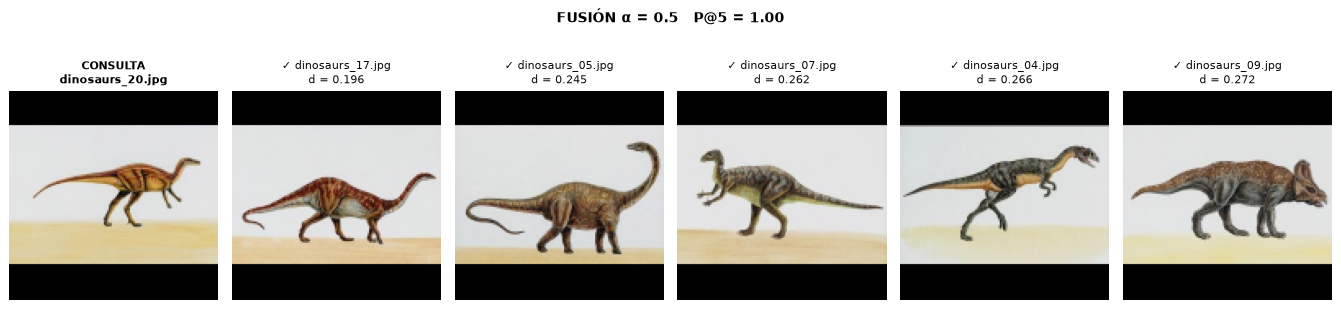

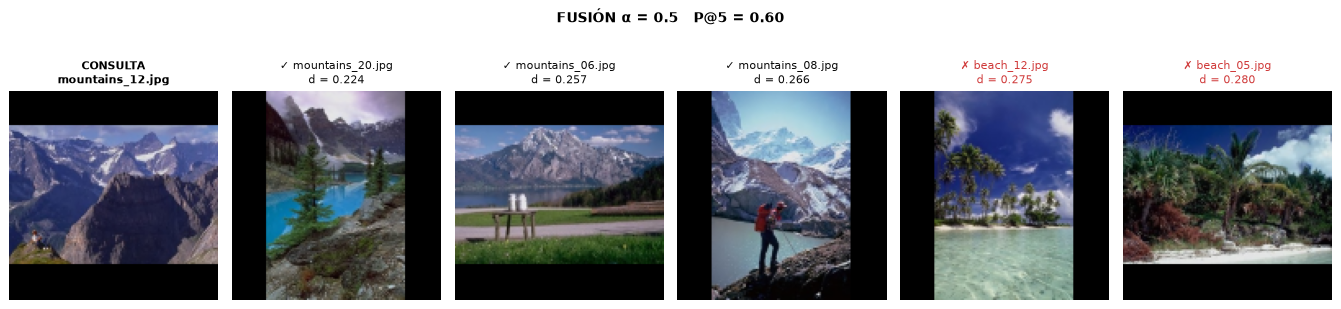

In [19]:
mostrar(Q[2], buscar_fusion(Q[2], 0.5), f'FUSIÓN α = 0.5')
mostrar(Q[1], buscar_fusion(Q[1], 0.5), f'FUSIÓN α = 0.5')

## 6. Análisis

### Caso 1: el color funciona mejor (`flowers_18`, color P@5 = 1.00 contra textura P@5 = 0.00)
Con el color, las 5 recuperadas son rosas: todas comparten fondo oscuro, hojas verdes y pétalos de tonos cálidos. Con la textura no recupera ninguna flor: devuelve dinosaurios con fondo blanco y playas. La GLCM solo ve dos números, y una imagen con mucha zona lisa da contraste bajo y homogeneidad alta **sin importar si la zona lisa es un fondo negro, un fondo blanco o el cielo**. Al ignorar el color, la textura no puede separar esas fotos.

### Caso 2: la textura funciona mejor (`mountains_12`, textura P@5 = 1.00 contra color P@5 = 0.20)
Con la textura, las 5 son montañas: rocas, nieve y sombras producen un contraste parecido. Con el color, 4 de 5 son errores (tres autobuses y una playa). La foto de consulta es cielo azul con rocas grises, y esos mismos colores aparecen en escenas urbanas con cielo y asfalto. El histograma no sabe que el gris es roca en una foto y calle en otra.

### Caso 3: la fusión mejora (`dinosaurs_20`, color 0.60 y textura 0.40 → fusión α = 0.5: 1.00)
Cada descriptor se equivoca con **imágenes distintas**. El color mete un autobús rojo y una montaña nevada (tonos blancos y rojizos como el dinosaurio). La textura mete rosas con fondo oscuro (zonas lisas como el fondo blanco). Las otras imágenes de dinosaurios están cerca en **ambos** descriptores, así que al combinar las distancias suben al Top-5 y los errores de cada uno quedan fuera.

### Caso 4: la fusión empeora (`mountains_12`, textura 1.00 → α = 0.5: 0.60)
Si un descriptor es claramente malo para esa consulta, mezclarlo arrastra el resultado. Con α = 0.5 entran dos playas (`beach_12`, `beach_05`) que tienen el mismo cielo azul intenso. A partir de α = 0.25, cuanto más peso tiene el color, peor es el P@5 (0.8 → 0.6 → 0.6 → 0.2).

### Promedio de las 100 consultas
| | solo textura (α = 0) | solo color (α = 1) | mejor fusión (α = 0.75) |
|---|---|---|---|
| P@5 | 0.546 | 0.668 | **0.748** |

- La fusión mejora sobre todo a las **flores** (0.69 → 0.97) y a los **autobuses** (0.88 → 0.94).
- **Beach** y **Mountains** son las categorías difíciles en cualquier configuración (≤ 0.46), porque comparten cielo azul y paisaje.
- Aunque en `mountains_12` ganó la textura, en promedio la clase Mountains rinde un poco mejor con color (0.40 contra 0.32). Una sola consulta no basta para generalizar.

## Preguntas de reflexión

**1. ¿Por qué dos imágenes de categorías distintas pueden tener histogramas HSV parecidos?**
Porque el histograma solo cuenta cuántos píxeles hay de cada color: no guarda dónde están ni a qué objeto pertenecen. Una playa y una montaña tienen el mismo cielo azul. Un autobús en la ciudad tiene el mismo gris que una roca. En esta colección, además, el fondo pesa mucho: el fondo oscuro de las flores ocupa un tercio del histograma. Por eso `mountains_12` recupera autobuses con el descriptor de color.

**2. ¿Cómo afecta la cuantización de 8 niveles a la información de textura?**
Cada nivel agrupa 32 tonos de gris (256 / 8). Las variaciones finas, menores a unos 32 tonos, desaparecen porque los dos píxeles caen en el mismo nivel y el par se cuenta en la diagonal.
- **Ventajas:** la GLCM queda de 8×8 (64 celdas), es más rápida y es menos sensible al ruido.
- **Desventaja:** pierde detalle, sobre todo en imágenes oscuras o de poco contraste. La rosa flowers_15 concentra casi toda su GLCM en los niveles 0–1 y obtiene el contraste más bajo de la colección (0.108), aunque sus pétalos sí tienen textura.

**3. ¿Qué significa que una GLCM tenga valores altos sobre la diagonal principal?**
Que la mayoría de los pares de vecinos (d = 1, 0°) tienen el mismo nivel de gris, o sea, que la imagen tiene zonas lisas o uniformes. Entonces el contraste es cercano a y la homogeneidad es cercana a 1 . Siendo una vez mas flowers_15 la tiene alrededor del 90 % de su probabilidad en la diagonal, con C = 0.108 y H = 0.949.

**4. ¿Por qué es necesario normalizar las distancias antes de combinarlas?**
Porque están en escalas distintas. La distancia de color va de 0 a 0.82 y la de textura de 0 a 6.0, unas 7 veces más grande. Sin normalizar, con α = 0.5 la textura dominaría la suma y α no representaría el peso real de cada descriptor. Al dividir entre el máximo de la colección, ambas quedan entre 0 y 1. Como la regla es **fija** (se calcula sobre la colección y no por consulta), un mismo α significa lo mismo en todas las consultas y las distancias se pueden comparar entre consultas. Por la misma razón se estandarizaron el contraste y la homogeneidad antes de calcular la distancia de textura.

**5. ¿Qué limitaciones tiene evaluar relevancia solo por pertenencia a una categoría?**
- **Es binaria y gruesa.** Una playa con montañas al fondo cuenta como "no relevante" para una consulta de montaña, aunque visualmente se parezca mucho.
- **No refleja la intención del usuario.** Quien busca con la foto de un autobús rojo quizá quiere "cosas rojas", no "autobuses".
- **No hay grados de relevancia** (muy, poco o nada relevante), y P@5 tampoco considera el orden dentro del Top-5. AP o MAP sí lo harían.
- **Mezcla dos cosas distintas.** La categoría es un concepto **semántico**, mientras que los descriptores miden **similitud visual**. Un sistema puede devolver imágenes visualmente muy parecidas y salir castigado: es la brecha semántica.

## Conclusiones

Ningún descriptor basta por sí solo. Con las 100 imágenes como consulta, el histograma HSV logra P@5 = 0.67 y la GLCM (contraste y homogeneidad) 0.55. La fusión con α = 0.75 sube a 0.75. En las tres consultas elegidas, el promedio pasa de 0.60 (color) y 0.47 (textura) a 0.87 con α = 0.5 o 0.75.

El color funciona cuando la categoría tiene una paleta propia: flores sobre fondo oscuro, con P@5 = 1.0 en `flowers_18`. Pero confunde escenas que comparten colores sin compartir contenido: para `mountains_12` devuelve autobuses y una playa porque todos tienen cielo azul y grises. La textura distingue las montañas, pero con solo dos números confunde cualquier imagen con grandes zonas lisas: a `flowers_18` le devuelve dinosaurios con fondo blanco.

La fusión ayuda cuando cada descriptor se equivoca en imágenes distintas (`dinosaurs_20`: 0.6 y 0.4 → 1.0). En cambio, empeora cuando uno de ellos es claramente malo para esa consulta (`mountains_12`: 1.0 → 0.6 con α = 0.5). Normalizar con una regla fija de la colección es indispensable: sin ella, la distancia de textura (hasta 6.0) dominaría a la de color (hasta 0.82).

Por último, la similitud visual no es lo mismo que la relevancia semántica. Beach y Mountains se quedan por debajo de 0.5 en todas las configuraciones, porque lo que las define (mar, montaña) no se reduce a colores globales ni a dos propiedades de textura.